| Roll No.| Subject Code | Assignment No. |
|:-------:|:------------:|:--------------:|
| 2650026 | CS69101      | Lab 8          |

# Implementation

Implement a Binary Min Heap using an array.

Your implementation must support:
1. Construct a Min Heap from the given unsorted array using bottom-up heap construction.
2. Insert a new element into the Min Heap.
3. Find the minimum element.
4. Extract-Min operation.
5. Delete an arbitrary element
6. Decrease-Key operation for a specified element.
7. Display the heap after every operation.

In [1]:
import sys
from io import TextIOWrapper
from typing import Self, Any, Callable, TypeVar, Generic, Optional
import random
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pylab import figure

sys.setrecursionlimit(100000) # Fix to avoid RecursionError

prep_arr = [random.randint(1, (i+1)*10) for i in range(100000)] # Random Array of 100000 Elements
# prep_arr.sort() # Sorted Array for Worst Case Scenario
print(prep_arr[:25])
print(len(prep_arr))

# Write the array to a file
f = open("./2650026_lab8_data/input0.txt", "w")
for i in prep_arr:
    f.write(f"{i}, ")
f.write("\n")
f.close()

del prep_arr
del f

iterations = 0
swaps = 0
PRINT_DEBUG = False

[1, 13, 29, 28, 41, 8, 68, 29, 82, 15, 57, 107, 72, 88, 41, 118, 14, 145, 113, 128, 103, 29, 55, 137, 4]
100000


In [2]:
def get_random_sample(arr, n):
    if n > len(arr):
        raise ValueError("n cannot exceed the array length")

    start = random.randint(0, len(arr) - n)
    return arr[start : start + n]

In [3]:
class MinHeap:
    def __init__(self, arr: list[int] | None = None):
        if arr is None:
            self.arr = []
        else:
            self.arr = arr
        self.size = len(self.arr)
        self.bottom_up_build_min_heap()

    def _parent_index(self, i: int) -> int:
        return (i - 1) // 2

    def _left_child_index(self, i: int) -> int:
        return 2 * i + 1

    def _right_child_index(self, i: int) -> int:
        return 2 * i + 2

    def get_min(self) -> int:
        if self.size == 0:
            raise IndexError("[ERROR] Getting minimum from an empty heap.")
        return self.arr[0]

    def min_heapify(self, i: int):
        global iterations, swaps
        iterations += 1

        left = self._left_child_index(i)
        right = self._right_child_index(i)
        # Find the index of the smallest element among the current node and its children
        if left < self.size and self.arr[left] < self.arr[i]:
            smallest = left
        else:
            smallest = i

        if right < self.size and self.arr[right] < self.arr[smallest]:
            smallest = right

        if smallest != i:
            self.arr[i], self.arr[smallest] = self.arr[smallest], self.arr[i]
            swaps += 1
            if PRINT_DEBUG:
                print(f"Swapped {self.arr[i]} and {self.arr[smallest]} at indices {i} and {smallest}")
            self.min_heapify(smallest)

    def bottom_up_build_min_heap(self, arr: list[int] | None = None):
        if arr is not None:
            self.arr = arr
            self.size = len(self.arr)
        for i in range(self.size // 2 - 1, -1, -1):
            self.min_heapify(i)

    def top_down_build_min_heap(self, arr: list[int] | None = None):
        if arr is not None:
            self.arr = arr
            self.size = len(self.arr)
        for i in range(self.size):
            self.decrease_key(i, self.arr[i])

    def extract_min(self) -> int:
        if self.size == 0:
            raise IndexError("[ERROR] Extracting from an empty heap.")
        min_value = self.arr[0]
        self.arr[0] = self.arr[self.size - 1]
        self.size -= 1
        self.arr.pop()  # Remove the last element
        self.min_heapify(0)
        return min_value

    def min_heap_insert(self, value: int):
        global iterations, swaps
        iterations += 1

        self.arr.append(value)
        self.size += 1
        i = self.size - 1
        while i > 0 and self.arr[self._parent_index(i)] > self.arr[i]:
            parent = self._parent_index(i)
            self.arr[i], self.arr[parent] = self.arr[parent], self.arr[i]
            swaps += 1
            iterations += 1
            if PRINT_DEBUG:
                print(f"Swapped {self.arr[i]} and {self.arr[parent]} at indices {i} and {parent}")
            i = parent

    def min_heap_delete(self, i: int):
        global iterations, swaps

        if i < 0 or i >= self.size:
            raise IndexError("[ERROR] Index out of bounds.")
        self.size -= 1
        last_value = self.arr.pop()  # Remove the last element
        if i == self.size:
            return
        self.arr[i] = last_value
        if i > 0 and self.arr[i] < self.arr[self._parent_index(i)]:
            while i > 0:
                parent = self._parent_index(i)
                if self.arr[parent] <= self.arr[i]:
                    break
                self.arr[i], self.arr[parent] = self.arr[parent], self.arr[i]
                swaps += 1
                iterations += 1
                i = parent
        else:
            self.min_heapify(i)

    def decrease_key(self, i: int, new_value: int):
        global iterations, swaps
        iterations += 1

        if new_value > self.arr[i]:
            raise ValueError("[ERROR] New value is greater than the current value.")
        self.arr[i] = new_value
        while i > 0 and self.arr[self._parent_index(i)] > self.arr[i]:
            parent = self._parent_index(i)
            self.arr[i], self.arr[parent] = self.arr[parent], self.arr[i]
            swaps += 1
            iterations += 1
            if PRINT_DEBUG:
                print(f"Swapped {self.arr[i]} and {self.arr[parent]} at indices {i} and {parent}")
            i = parent

    def heap_search(self, i: int = 0, value: int = 0) -> int:
        global iterations
        iterations += 1

        if self.size == 0:
            return -1
        if i >= self.size or self.arr[i] > value:
            return -1
        if self.arr[i] == value:
            return i
        left_res = self.heap_search(self._left_child_index(i), value)
        if left_res != -1:
            return left_res
        return self.heap_search(self._right_child_index(i), value)

    def __str__(self) -> str:
        return str(self.arr[:self.size])

    def __repr__(self) -> str:
        return f"MinHeap({self.arr[:self.size]})"

Given an unsorted array of N distinct integers, design an algorithm to identify the Kth smallest element using a Min Heap.

In [4]:
def kth_smallest_min_heap(self, N, k: int) -> int:
    if k < 1 or k > N:
        raise ValueError("[ERROR] k is out of bounds.")
    min_heap = MinHeap(self.arr[:N])
    for _ in range(1, k):
        min_heap.extract_min()
    return min_heap.get_min()

# Testing Implementation for above stated operations

In [5]:
# Read a set of integer elements from an input file (input.txt)
arr0 = []
data0 = open("./2650026_lab8_data/input.txt", 'r')
try:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(',',' ').split() #using rstrip to remove the \n
        for data in line_data:
            arr0.append(int(data))
        data0.close()
except Exception as e:
    data0.close()
    sys.exit("[ERROR] Invalid data" + str(e))

In [6]:
minheap0 = MinHeap()
MinHeap.bottom_up_build_min_heap(minheap0, arr0)

In [7]:
print(minheap0)

[25, 50, 76, 67, 55, 210, 90, 77, 69, 420, 70, 911, 348, 108, 768, 1080, 720]


In [8]:
MinHeap.min_heap_insert(minheap0, 101)
print(minheap0)

[25, 50, 76, 67, 55, 210, 90, 77, 69, 420, 70, 911, 348, 108, 768, 1080, 720, 101]


In [9]:
minheap0.get_min()

25

In [10]:
minheap0.extract_min()

25

In [11]:
print(f"MinHeap after extract_min: {minheap0}")

MinHeap after extract_min: [50, 55, 76, 67, 70, 210, 90, 77, 69, 420, 101, 911, 348, 108, 768, 1080, 720]


In [12]:
idx_del = minheap0.heap_search(value=67)
if idx_del != -1:
    minheap0.min_heap_delete(idx_del)
print(f"MinHeap after deleting 67: {minheap0}")

MinHeap after deleting 67: [50, 55, 76, 69, 70, 210, 90, 77, 720, 420, 101, 911, 348, 108, 768, 1080]


In [13]:
minheap0.decrease_key(6, 67)

In [14]:
print(f"MinHeap after decreasing key at index 6 to 67: {minheap0}")

MinHeap after decreasing key at index 6 to 67: [50, 55, 67, 69, 70, 210, 76, 77, 720, 420, 101, 911, 348, 108, 768, 1080]


In [15]:
print(f"7th smallest element in the MinHeap: {kth_smallest_min_heap(minheap0, len(minheap0.arr), 7)}")

7th smallest element in the MinHeap: 77


In [16]:
def MinHeap_Verify(heap: MinHeap) -> None:
    assert heap.size == len(heap.arr), "size and array length differ"
    for i in range(1, heap.size):
        assert heap.arr[heap._parent_index(i)] <= heap.arr[i], f"min-heap property is broken at index {i}"

MinHeap_Verify(minheap0)

# The k-th smallest element must agree with the sorted order for every k
sorted_elements = sorted(minheap0.arr)
for k in range(1, len(minheap0.arr) + 1):
    assert kth_smallest_min_heap(minheap0, len(minheap0.arr), k) == sorted_elements[k - 1], f"k = {k} is wrong"
print("The min-heap property holds and the k-th smallest element is correct for every k.")

The min-heap property holds and the k-th smallest element is correct for every k.


# Performance Evaluation

Evaluate the performance of your Min Heap implementation for the following input sizes:
N = 1,000; 5,000; 10,000; 50,000; 100,000.

Conduct experiments using:
1. Randomly generated input.
2. Ascending sorted input.
3. Descending sorted input.

In [17]:
arr1 = []
with open("./2650026_lab8_data/input0.txt", 'r') as data0:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(' ','').split(',')
        for data in line_data:
            arr1.append(int(data))

SIZES = [1000, 5000, 10000, 50000, 100000]
N = SIZES[-1]
ORDERS = ["Random", "Ascending Sorted", "Descending Sorted"]

random.seed(911)

def Heap_Bottom_Up_Measured(values: list[int]):
    global iterations, swaps
    iterations = 0
    swaps = 0
    heap = MinHeap(values[:])  # the constructor builds the heap bottom-up
    return heap, iterations, swaps


def Heap_Top_Down_Measured(values: list[int]):
    global iterations, swaps
    heap = MinHeap()
    iterations = 0
    swaps = 0
    heap.top_down_build_min_heap(values[:])
    return heap, iterations, swaps


def Heap_Insert_Recorded(values: list[int]) -> dict:
    global iterations, swaps
    heap = MinHeap()
    iteration_counts, swap_counts = [], []
    for value in values:
        iterations = 0
        swaps = 0
        heap.min_heap_insert(value)
        iteration_counts.append(iterations)
        swap_counts.append(swaps)
    MinHeap_Verify(heap)
    return {"Iterations": iteration_counts, "Swaps": swap_counts}


def Heap_Extract_Recorded(values: list[int]) -> dict:
    global iterations, swaps
    heap = MinHeap(values[:])
    iteration_counts, swap_counts, extracted = [], [], []
    for _ in range(len(values)):
        iterations = 0
        swaps = 0
        extracted.append(heap.extract_min())
        iteration_counts.append(iterations)
        swap_counts.append(swaps)
    assert extracted == sorted(values), "repeated extract-min must return the elements in sorted order"
    # Extractions were recorded from the full heap downwards: reverse them so that index j belongs to heap size j + 1
    return {"Iterations": iteration_counts[::-1], "Swaps": swap_counts[::-1]}


def Heap_Search_Measured(heap: MinHeap, key: int):
    global iterations
    iterations = 0
    index = heap.heap_search(value=key)
    return index, iterations

In [18]:
construction_rows, insertion_rows, extract_rows, search_rows = [], [], [], []
records = {}  # per-operation data of the largest size

for n in SIZES:
    window = get_random_sample(arr1, n)
    input_orders = {
        "Random": window,
        "Ascending Sorted": sorted(window),
        "Descending Sorted": sorted(window, reverse=True),
    }

    existing_keys = random.sample(window, min(100, n))
    present = set(window)
    missing_keys = []
    while len(missing_keys) < 100:
        key = random.randint(1, max(window))
        if key not in present:
            missing_keys.append(key)

    for order_name, values in input_orders.items():
        # Bottom-up and top-down heap construction
        heap, bottom_up_iterations, bottom_up_swaps = Heap_Bottom_Up_Measured(values)
        MinHeap_Verify(heap)
        top_down_heap, top_down_iterations, top_down_swaps = Heap_Top_Down_Measured(values)
        MinHeap_Verify(top_down_heap)
        construction_rows.append({
            "Elements": n, "Input Order": order_name,
            "Bottom-Up Iterations": bottom_up_iterations, "Bottom-Up Swaps": bottom_up_swaps,
            "Top-Down Iterations": top_down_iterations, "Top-Down Swaps": top_down_swaps,
        })

        # Insertion of n elements, one by one into an empty heap
        insertion = Heap_Insert_Recorded(values)
        insertion_rows.append({
            "Elements": n, "Input Order": order_name,
            "Total Iterations": sum(insertion["Iterations"]), "Total Swaps": sum(insertion["Swaps"]),
            "Average Iterations per Insertion": sum(insertion["Iterations"]) / n,
            "Average Swaps per Insertion": sum(insertion["Swaps"]) / n,
        })

        # Repeated extract-min until the heap is empty
        extraction = Heap_Extract_Recorded(values)
        extract_rows.append({
            "Elements": n, "Input Order": order_name,
            "Total Iterations": sum(extraction["Iterations"]), "Total Swaps": sum(extraction["Swaps"]),
            "Average Iterations per Extract-Min": sum(extraction["Iterations"]) / n,
            "Average Swaps per Extract-Min": sum(extraction["Swaps"]) / n,
        })

        if n == N:
            records[(order_name, "Insertion")] = insertion
            records[(order_name, "Extract-Min")] = extraction

        # Searching in the bottom-up heap: 100 existing and 100 non-existing elements
        existing_counts, missing_counts = [], []
        for key in existing_keys:
            index, count = Heap_Search_Measured(heap, key)
            assert index != -1 and heap.arr[index] == key, f"{key} must be found"
            existing_counts.append(count)
        for key in missing_keys:
            index, count = Heap_Search_Measured(heap, key)
            assert index == -1, f"{key} must not be found"
            missing_counts.append(count)
        search_rows.append({
            "Elements": n, "Input Order": order_name,
            "Existing Average Iterations": sum(existing_counts) / len(existing_counts),
            "Non-Existing Average Iterations": sum(missing_counts) / len(missing_counts),
        })

construction_df = pd.DataFrame(construction_rows)
insertion_df = pd.DataFrame(insertion_rows)
extract_df = pd.DataFrame(extract_rows)
search_df = pd.DataFrame(search_rows)

In [19]:
construction_df

,Elements,Input Order,Bottom-Up Iterations,Bottom-Up Swaps,Top-Down Iterations,Top-Down Swaps
0,1000,Random,1229,729,2234,1234
1,1000,Ascending Sorted,500,0,1000,0
2,1000,Descending Sorted,1492,992,8984,7984
3,5000,Random,6118,3618,11290,6290
4,5000,Ascending Sorted,2500,0,5000,0
5,5000,Descending Sorted,7493,4993,56805,51805
6,10000,Random,11928,6928,21474,11474
7,10000,Ascending Sorted,5000,0,10000,0
8,10000,Descending Sorted,14992,9992,123460,113460
9,50000,Random,53115,28115,92056,42056


Measure the execution time for:
- Bottom-up heap construction.
- Top-down heap construction.
- Insertion of N elements.
- Repeated Extract-Min operations.
- Searching for an existing element.
- Searching for a non-existing element.

Record:
- Execution time (or Number of Iterations)
- Number of swaps.

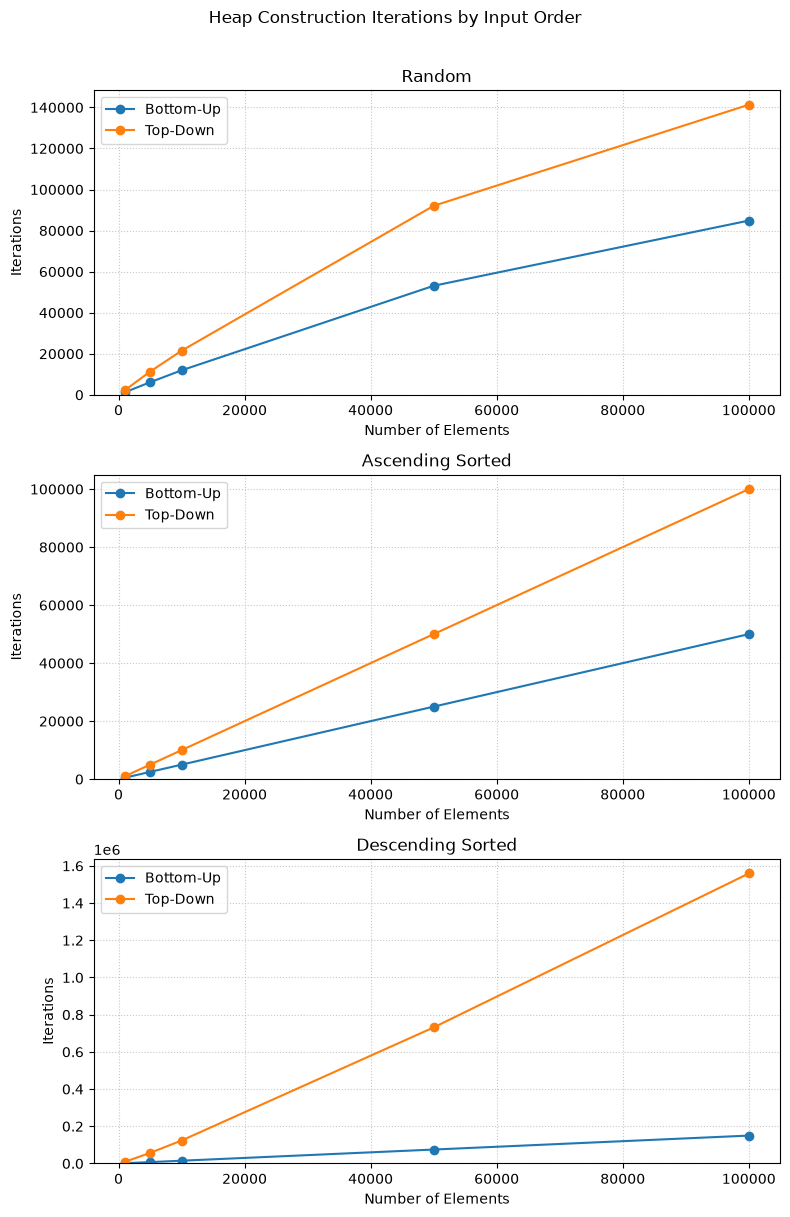

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = construction_df[construction_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Bottom-Up Iterations"], marker="o", label="Bottom-Up")
    ax.plot(subset["Elements"], subset["Top-Down Iterations"], marker="o", label="Top-Down")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Iterations")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Heap Construction Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/construction_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

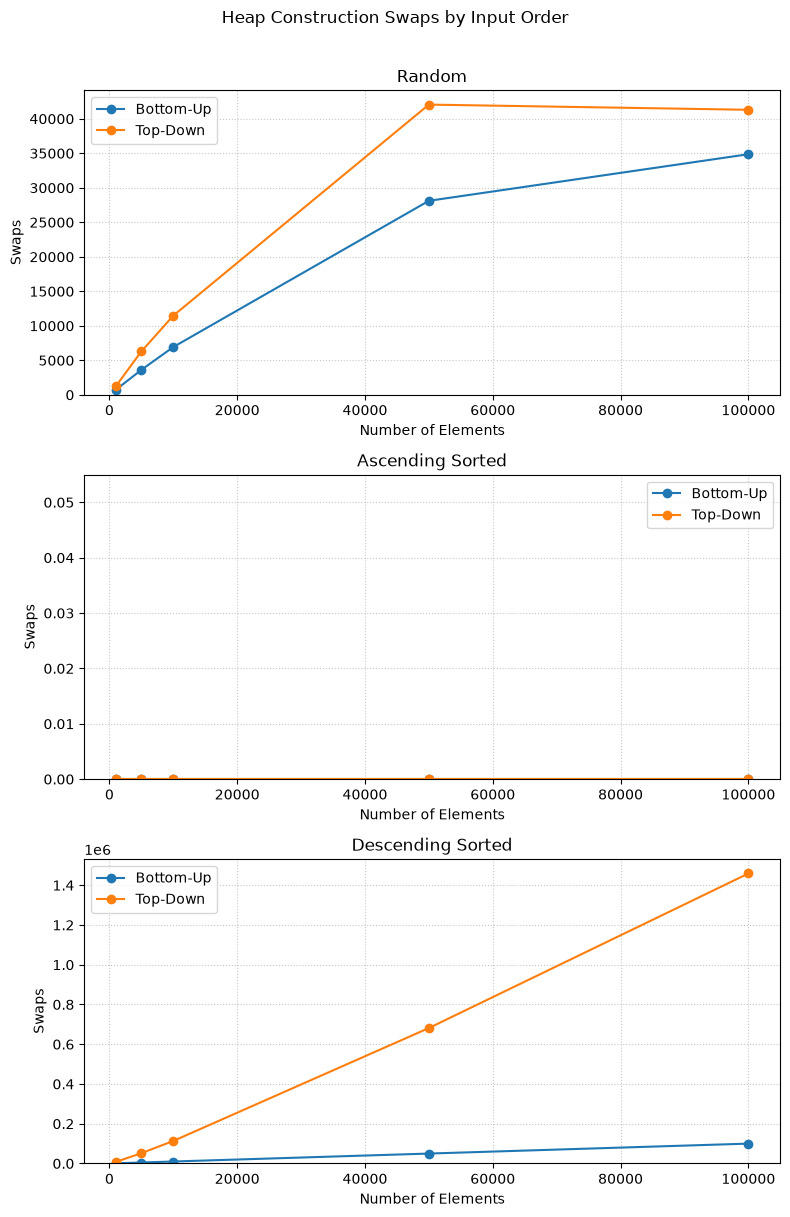

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = construction_df[construction_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Bottom-Up Swaps"], marker="o", label="Bottom-Up")
    ax.plot(subset["Elements"], subset["Top-Down Swaps"], marker="o", label="Top-Down")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Swaps")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Heap Construction Swaps by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/construction_swaps.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
insertion_df

,Elements,Input Order,Total Iterations,Total Swaps,Average Iterations per Insertion,Average Swaps per Insertion
0,1000,Random,2234,1234,2.23400,1.23400
1,1000,Ascending Sorted,1000,0,1.00000,0.00000
2,1000,Descending Sorted,8984,7984,8.98400,7.98400
3,5000,Random,11290,6290,2.25800,1.25800
4,5000,Ascending Sorted,5000,0,1.00000,0.00000
5,5000,Descending Sorted,56805,51805,11.36100,10.36100
6,10000,Random,21474,11474,2.14740,1.14740
7,10000,Ascending Sorted,10000,0,1.00000,0.00000
8,10000,Descending Sorted,123460,113460,12.34600,11.34600
9,50000,Random,92056,42056,1.84112,0.84112


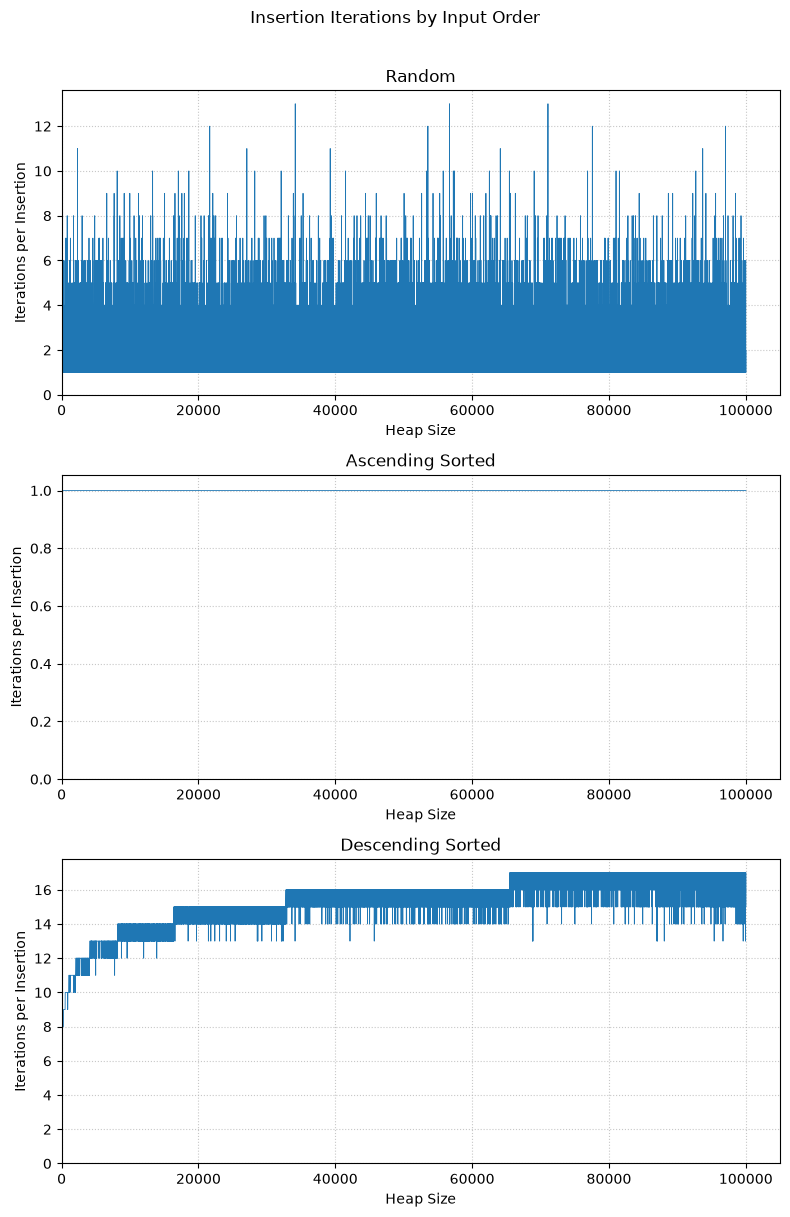

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Insertion")]["Iterations"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Iterations per Insertion")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Insertion Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/insertion_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

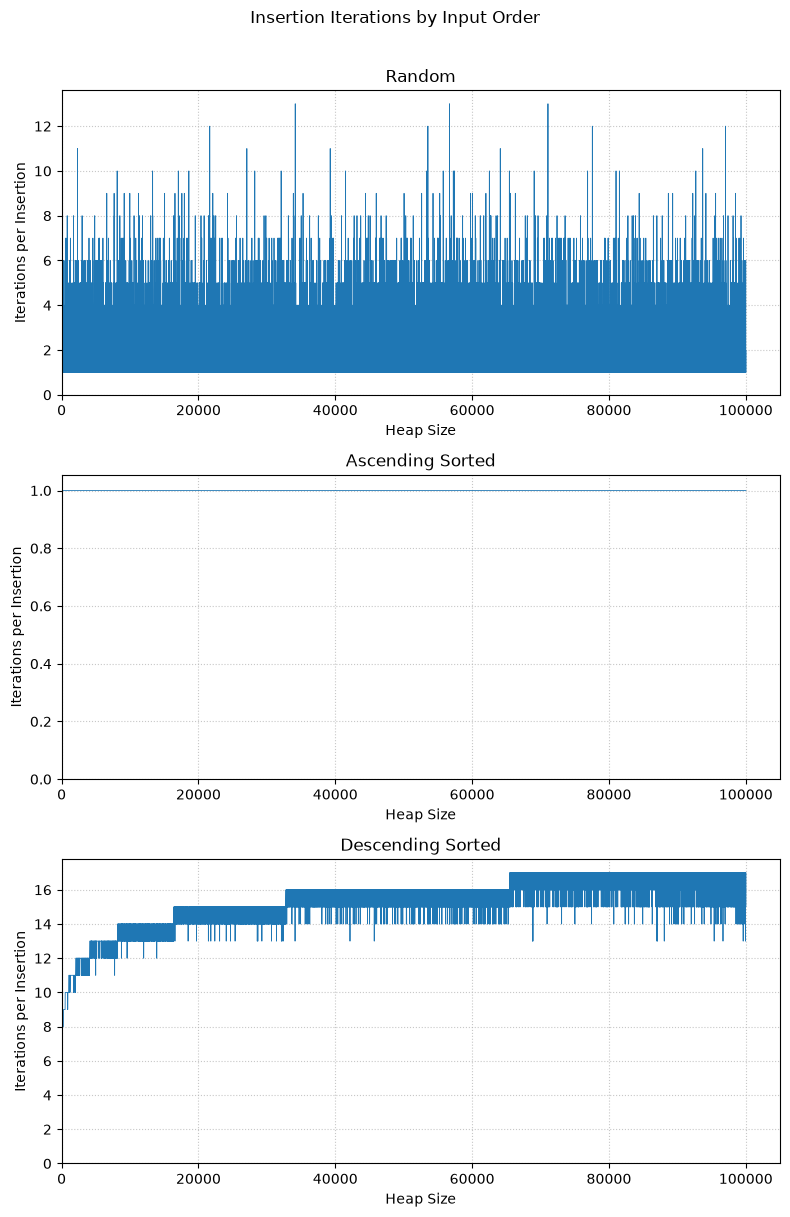

In [26]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Insertion")]["Iterations"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Iterations per Insertion")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Insertion Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/insertion_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

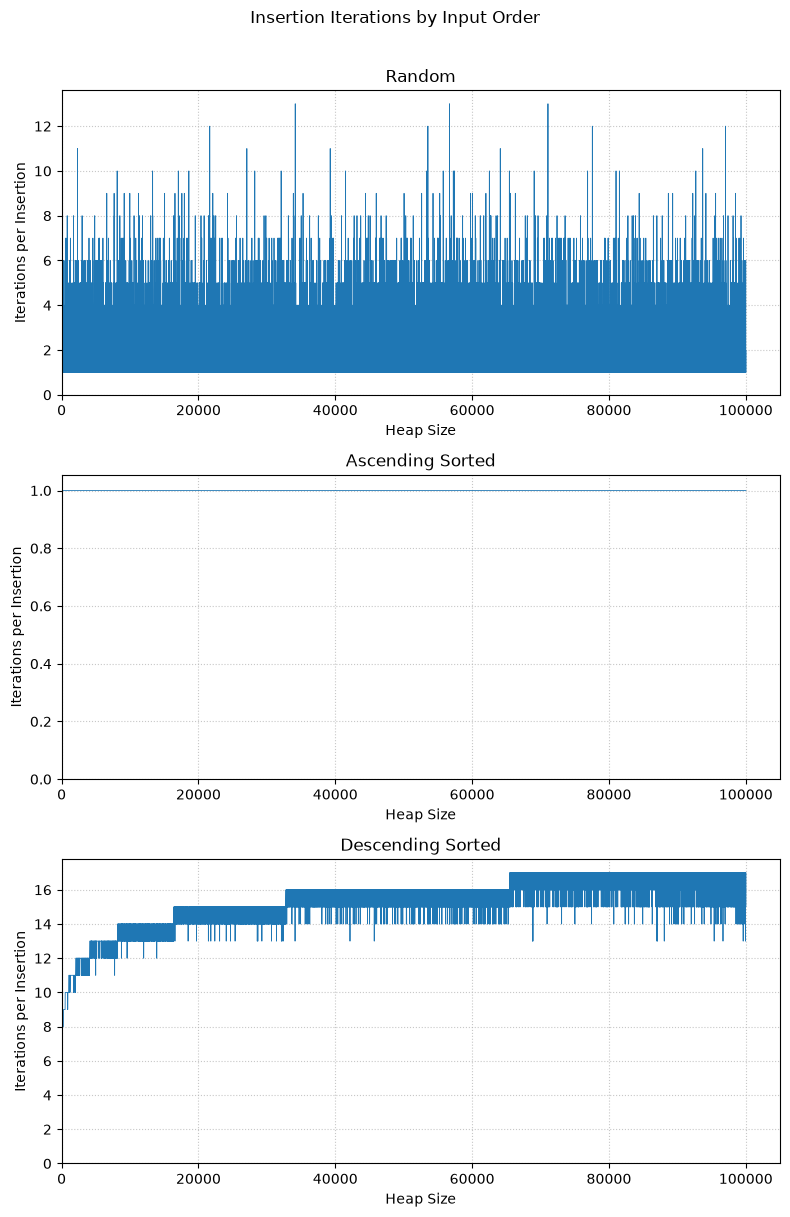

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Insertion")]["Iterations"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Iterations per Insertion")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Insertion Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/insertion_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
extract_df

,Elements,Input Order,Total Iterations,Total Swaps,Average Iterations per Extract-Min,Average Swaps per Extract-Min
0,1000,Random,8338,7338,8.33800,7.33800
1,1000,Ascending Sorted,8315,7315,8.31500,7.31500
2,1000,Descending Sorted,8719,7719,8.71900,7.71900
3,5000,Random,53400,48400,10.68000,9.68000
4,5000,Ascending Sorted,53434,48434,10.68680,9.68680
5,5000,Descending Sorted,55891,50891,11.17820,10.17820
6,10000,Random,116775,106775,11.67750,10.67750
7,10000,Ascending Sorted,116667,106667,11.66670,10.66670
8,10000,Descending Sorted,121653,111653,12.16530,11.16530
9,50000,Random,700792,650792,14.01584,13.01584


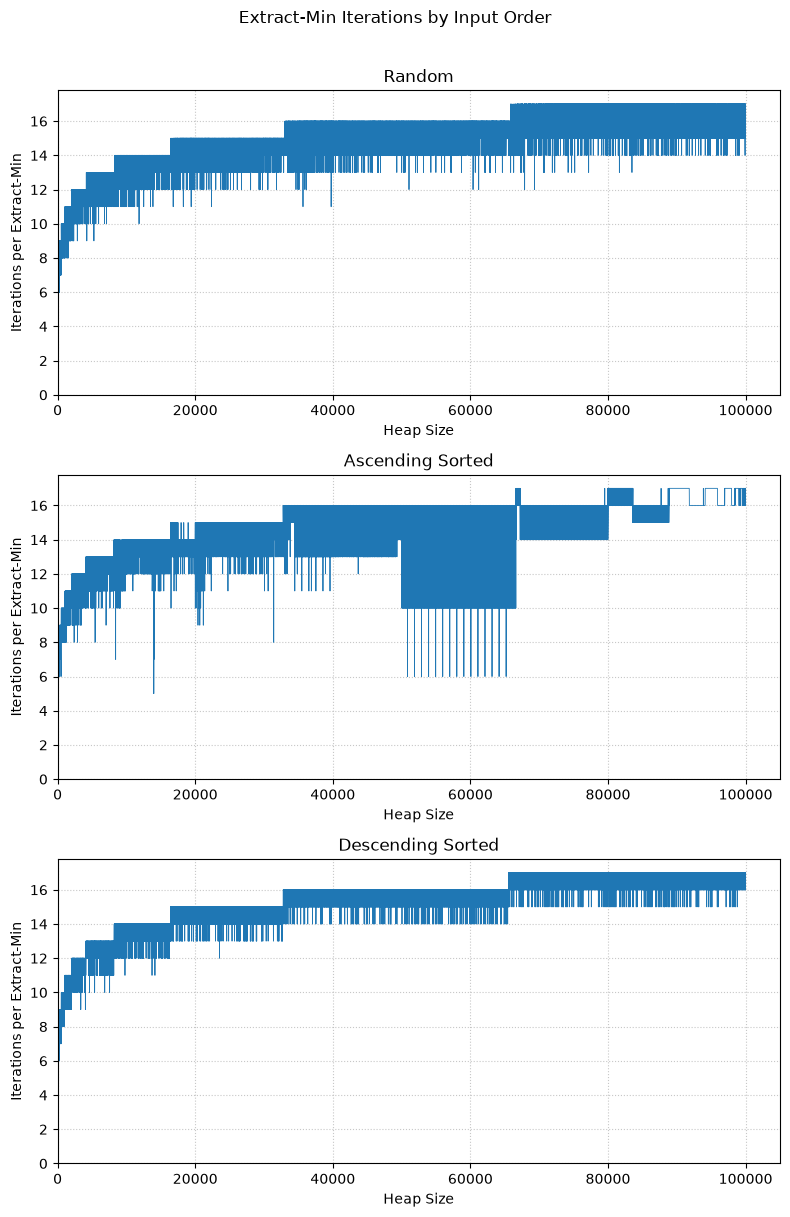

In [29]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Extract-Min")]["Iterations"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Iterations per Extract-Min")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Extract-Min Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/extract_min_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

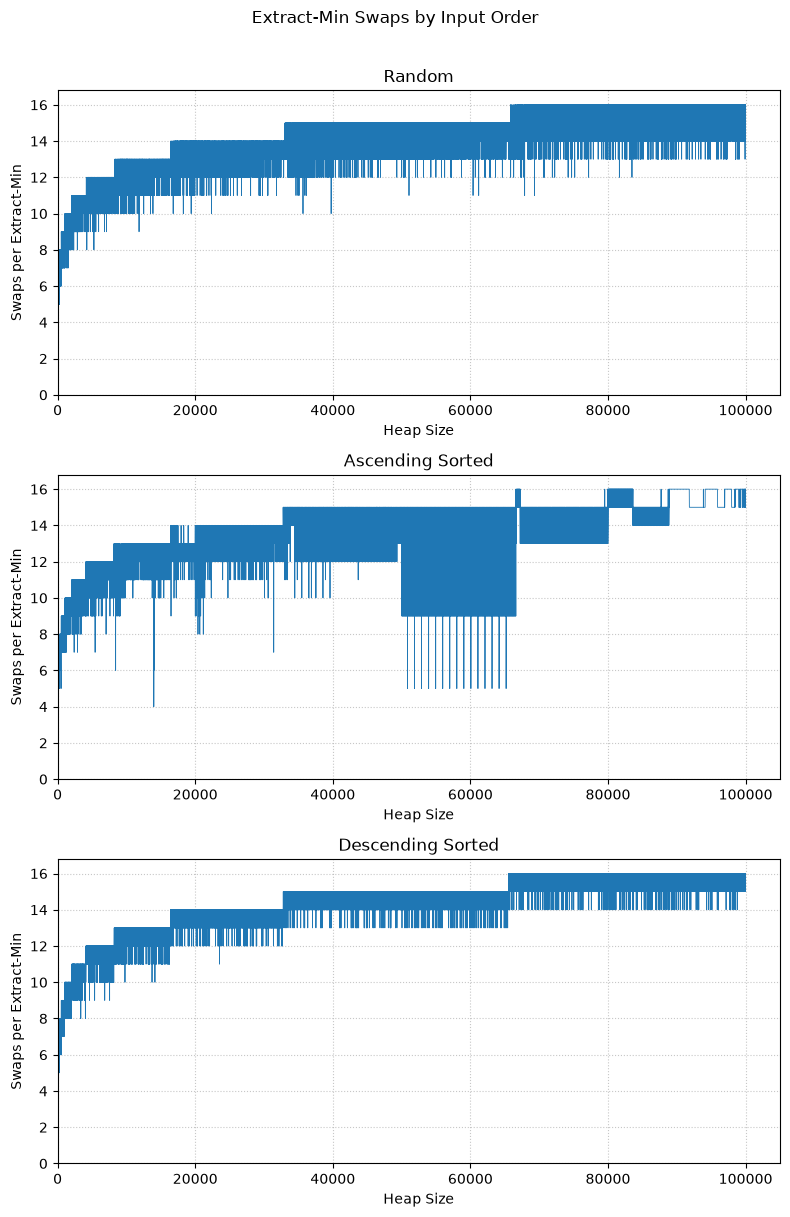

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    y = records[(order_name, "Extract-Min")]["Swaps"]
    x = [i+1 for i in range(len(y))]
    ax.plot(x, y, linewidth=0.6)
    ax.set_title(order_name)
    ax.set_xlabel("Heap Size")
    ax.set_ylabel("Swaps per Extract-Min")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Extract-Min Swaps by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/extract_min_swaps.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
search_df

,Elements,Input Order,Existing Average Iterations,Non-Existing Average Iterations
0,1000,Random,519.03,1044.92
1,1000,Ascending Sorted,625.49,1044.92
2,1000,Descending Sorted,338.75,1044.92
3,5000,Random,2619.22,4708.14
4,5000,Ascending Sorted,2654.11,4708.14
5,5000,Descending Sorted,2872.93,4708.14
6,10000,Random,5208.73,10528.10
7,10000,Ascending Sorted,5388.77,10528.10
8,10000,Descending Sorted,4971.31,10528.10
9,50000,Random,23232.29,68569.56


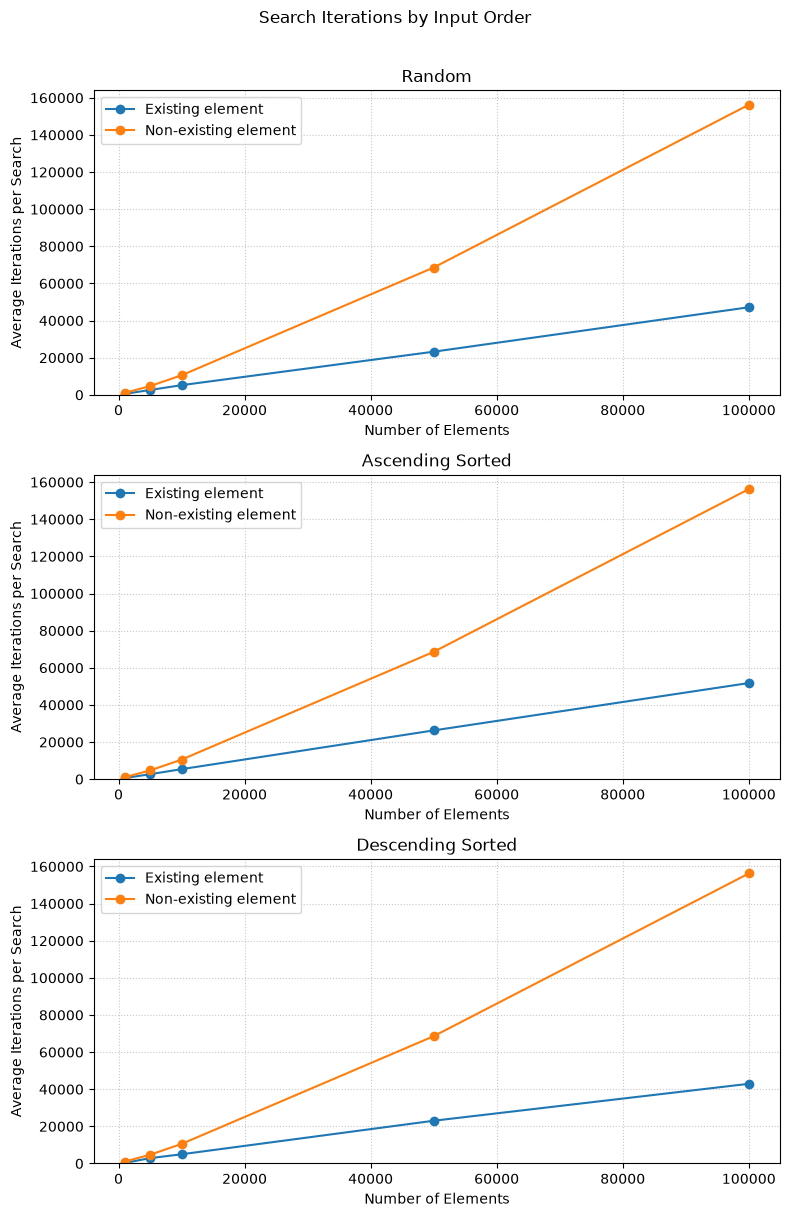

In [32]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = search_df[search_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Existing Average Iterations"], marker="o", label="Existing element")
    ax.plot(subset["Elements"], subset["Non-Existing Average Iterations"], marker="o", label="Non-existing element")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Average Iterations per Search")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Search Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/search_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

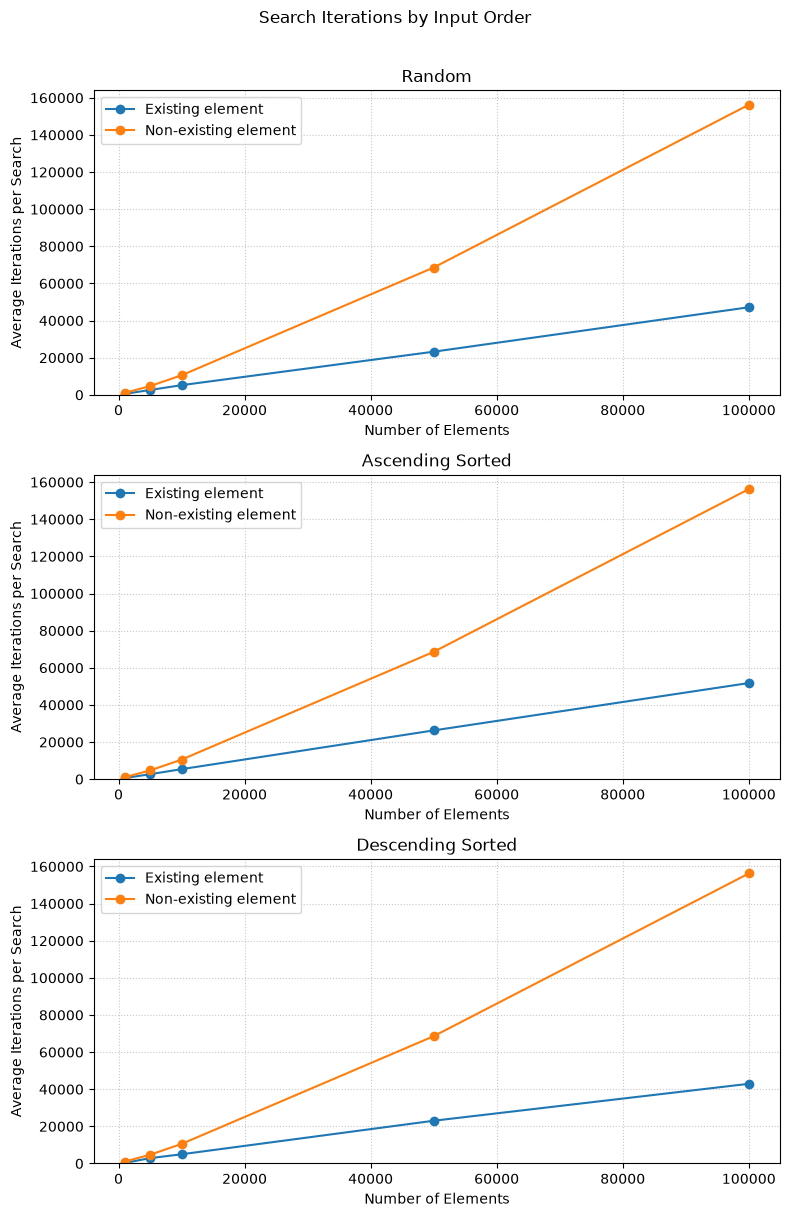

In [33]:
fig, axes = plt.subplots(3, 1, figsize=(8, 12))
for ax, order_name in zip(axes, ORDERS):
    subset = search_df[search_df["Input Order"] == order_name]
    ax.plot(subset["Elements"], subset["Existing Average Iterations"], marker="o", label="Existing element")
    ax.plot(subset["Elements"], subset["Non-Existing Average Iterations"], marker="o", label="Non-existing element")
    ax.set_title(order_name)
    ax.set_xlabel("Number of Elements")
    ax.set_ylabel("Average Iterations per Search")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle=":", alpha=0.7)
    ax.legend()
fig.suptitle("Search Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./2650026_lab8_data/search_iterations.png", dpi=150, bbox_inches="tight")
plt.show()

### Save to CSV

In [ ]:
insertion_df.to_csv("./lab8_data/insertion_summary.csv", index=False)

# The series plotted in the two graphs above, one row per input order and heap size
insertion_graph_df = pd.DataFrame([
    {"Input Order": order_name, "Heap Size": i+1,
     "Iterations per Insertion": records[(order_name, "Insertion")]["Iterations"][i],
     "Swaps per Insertion": records[(order_name, "Insertion")]["Swaps"][i]}
    for order_name in ORDERS for i in range(N)
])
insertion_graph_df.to_csv("./lab8_data/insertion_graph_data.csv", index=False)

In [34]:
construction_df.to_csv("./2650026_lab8_data/construction_summary.csv", index=False)

In [35]:
extract_df.to_csv("./2650026_lab8_data/extract_min_summary.csv", index=False)

# The series plotted in the two graphs above, one row per input order and heap size
extract_graph_df = pd.DataFrame([
    {"Input Order": order_name, "Heap Size": i+1,
     "Iterations per Extract-Min": records[(order_name, "Extract-Min")]["Iterations"][i],
     "Swaps per Extract-Min": records[(order_name, "Extract-Min")]["Swaps"][i]}
    for order_name in ORDERS for i in range(N)
])
extract_graph_df.to_csv("./2650026_lab8_data/extract_min_graph_data.csv", index=False)

In [36]:
search_df.to_csv("./2650026_lab8_data/search_summary.csv", index=False)